# 5.3 Particle Filter for Robot Localization

When dealing with problems of a stochastic nature (meaning, the processes involved are random), there are two main approaches:

- The first approach is to work **analytically**, with an explicitly defined probability distribution (e.g., a Gaussian one), and estimate the parameters of that distribution. This is what we did with the Extended Kalman Filter.

- The second one is to generate many **random samples**, and follow what happens to each of them as they are subjected to the randomness of the process. Crucially, each of these samples represents a single, determined value, rather than a probability distribution, and is thus easier to work with. Techniques using this second approach are often referred to as *Monte Carlo Methods*, and are very common in many disciplines. 

In this chapter, we will see a sample-based technique for probabilistic estimation, and apply it to the problem of robot localization. This technique goes by multiple names, such as *Monte Carlo Localization*, but we will refer to it with the generic term of **Particle Filter**. Specifically, we will:
- Get an intuition about what a particle is ([section 5.3.1](#531)),
- Implement the building blocks of the filter ([section 5.3.2](#532)), and
- Put them all together to perform localization ([section 5.3.3](#533)).

In [1]:
# In case of using Google Colab, mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    # Change directory to this chapter's folder in your Drive copy of the course repo:
    %cd '/content/drive/MyDrive/Colab Notebooks/uma_robotics_2027/Chapter 05. Localization'
except ImportError:
    pass

# IMPORTS
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import copy
import cv2
import time
from collections import Counter
from IPython.display import display, clear_output

import sys
sys.path.append("..")
from utils.laser.laser2D import Laser2D
from utils.DrawRobot import DrawRobot
from utils.tcomp import tcomp
from utils.RemapRange import RemapRange
from utils.PlotEllipse import PlotEllipse
from laserUtils import LaserUtils

## 5.3.1 But, what is a particle? <a id="531"></a>

We can represent a probability distribution with a finite set of values by repeatedly sampling it, and that is precisely how particles are generated. What makes it a **particle**, rather than just a **sample**, is that a particle will later be transformed by *other* random samples: it holds a state, and that state can evolve over time. Let's see a toy example.

### Basic example

Let's say we have a random variable representing a position $[x,y]^T$, whose PDF is a 2D Gaussian. We want to move this position a certain amount to the right, but the movement itself has some uncertainty, also described by a Gaussian. How could we approximate the PDF of the result without propagating the uncertainty analytically (even though, of course, you do know how!)? Well, with particles! Have a look:

initial distribution: mean=(1.01, 1.00), variances=(1.00, 1.01)
Distribution after movement 1: mean=(11.05, 1.00), variances=(2.98, 2.02)
Distribution after movement 2: mean=(21.03, 0.99), variances=(5.02, 2.96)
Distribution after movement 3: mean=(31.03, 0.99), variances=(7.02, 3.98)


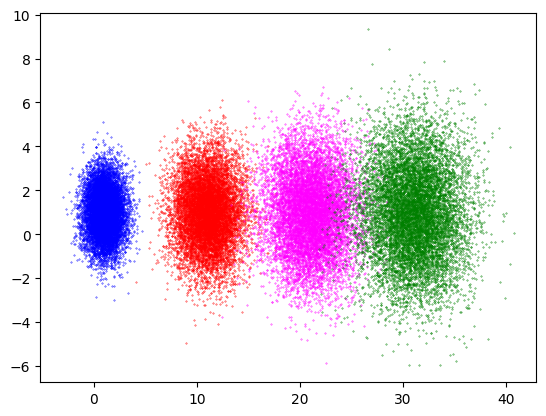

In [2]:
def basic_particles_example():
    num_particles = 10000
    start_mu = np.vstack([1, 1])
    start_sigma = np.diag([1, 1])

    # generate the particles by sampling the initial distribution
    particles = stats.multivariate_normal(start_mu.flatten(), start_sigma).rvs(num_particles)
    plt.scatter(particles[:,0], particles[:,1], s=0.1, color='blue')
    print("initial distribution: mean=({:.2f}, {:.2f}), variances=({:.2f}, {:.2f})".format(
        np.mean(particles[:,0]), np.mean(particles[:,1]), 
        np.var(particles[:,0]), np.var(particles[:,1])))


    colors= ['red', 'magenta', 'green']
    for i in range(3):
        # apply to each particle a single, random movement
        movement_mu = np.vstack([10, 0])
        movement_sigma = np.diag([2, 1])
        movement = stats.multivariate_normal(movement_mu.flatten(), movement_sigma).rvs(num_particles)

        particles += movement

        # plot the result
        plt.scatter(particles[:,0], particles[:,1], s=0.1, color=colors[i])
        print("Distribution after movement {:d}: mean=({:.2f}, {:.2f}), variances=({:.2f}, {:.2f})".format(
            i+1,
            np.mean(particles[:,0]), np.mean(particles[:,1]), 
            np.var(particles[:,0]), np.var(particles[:,1])))
    

basic_particles_example()

Hey, that's pretty good! It turns out we can propagate uncertainty just by drawing a random movement for each particle, and keeping track of where each one ends up.

However, the uncertainty always gets larger, so we end up not knowing where we are at all. To bring it back down, we need to use sensory data (**observations**) to evaluate how good each particle is. Basically, the question we want to ask is: *if the robot was at the pose represented by this particle, how well does my observation match what I would expect to see?* Then we can discard the bad particles and focus on the areas where good ones were found. That, in essence, is the Particle Filter.

More formally, the Particle Filter is a *Monte Carlo* implementation of the recursive Bayes filter: the belief about the robot pose, $bel(\mathbf{x}_t)$, is approximated by a set of $M$ weighted particles $\{\mathbf{x}_t^{[i]}, w_t^{[i]}\}_{i=1}^{M}$, where the weight $w_t^{[i]}$ measures how good the pose $\mathbf{x}_t^{[i]}$ of particle $i$ is. Unlike with the KF/EKF, this representation does not have to be Gaussian.

In the rest of this notebook, we will do this with a **laser scanner**, using the **likelihood field** model.

### Setting things up: occupancy map and likelihood field

Let's create a map, and use it to generate a **likelihood field**. Don't worry about the implementation details of the next cell: the important thing is what we get at the end.

In [3]:
class Map:
    def __init__(self, contours_map : np.ndarray, resolution : float):
        self.MIN_LIKELIHOOD = 0.1 # minimum value allowed in the likelihood field. Must be >0

        self.min_x, self.min_y = (np.nanmin(contours_map[0]), np.nanmin(contours_map[1]))
        self.max_x, self.max_y = (np.nanmax(contours_map[0]), np.nanmax(contours_map[1]))

        self.__margin_size = 1
        self.occupancy_img = np.full([int((self.max_y + self.__margin_size) / resolution), 
                       int((self.max_x + self.__margin_size) / resolution)],
                      255, np.uint8)
        
        self.width, self.height = self.occupancy_img.shape
        self.resolution = resolution

        # create dense image from contours
        #--------------------------------
        # split into multiple contours and arrange into a list of 1x2 vectors
        
        # split into a different array every time there is a nan
        indices = np.unique(np.where(np.isnan(contours_map))[1])
        contours = np.hsplit(contours_map, indices) 
        contours = [c[~np.isnan(c)].reshape(2, -1) for c in contours] # get rid of the actual nans, keeping the 2D shape

        # remove empty contours
        contours = [c for c in contours if c.size > 0]
        contours_formatted = [(c / resolution).astype('int32').T.reshape(-1, 1, 2) for c in contours]
        
        # draw the contours on the image
        cv2.polylines(self.occupancy_img, contours_formatted, False, (0,0,0))

        # calculate the likelihood field with a distance transform
        #--------------------------------
        self.likelihood_field = cv2.distanceTransform(self.occupancy_img, cv2.DIST_L2, 5)

        # calculate likelihood from the pixel distances
        SIGMA_HIT_M = 0.5 # set this to control how fast the likelihood decays as you get farther from the object
        sigma_hit_px = SIGMA_HIT_M / resolution

        self.likelihood_field = stats.norm(loc=0, scale=sigma_hit_px).pdf(self.likelihood_field)
        
        # remapping the values here to avoid having too-low values which will cause numerical issues upon repeated multiplication
        # the actual value here is therefore *proportional* to the likelihood, not the likelihood itself
        # but that's ok, because we will normalize the particle weights later :)
        self.likelihood_field = RemapRange(self.likelihood_field, 
                                           0, np.max(self.likelihood_field),
                                           self.MIN_LIKELIHOOD, 1)

    def sample_likelihood(self, point : np.ndarray):
        if point[0] < self.min_x or point[0] >= self.max_x or point[1] < self.min_y or point[1] >= self.max_y:
            return self.MIN_LIKELIHOOD
        indices = np.rint(np.flip(point / self.resolution, 0)).astype('int32')
        value = self.likelihood_field[tuple(indices)]
        return value
    
    def is_valid_position(self, point: np.ndarray):
        if point[0] < self.min_x or point[0] >= self.max_x or point[1] < self.min_y or point[1] >= self.max_y:
            return False
        indices = np.rint(np.flip(point / self.resolution, 0)).astype('int32')
        value = self.occupancy_img[tuple(indices)]
        return value[0] > 0


    # Visualization
    #-------------------------------------
    def show_occupancy(self):
        return self.__print_img(self.occupancy_img)

    def show_likelihood(self):
        return self.__print_img(self.likelihood_field)
    
    def __print_img(self, img):
        size_factor = 0.7
        fig, ax = plt.subplots(figsize=(self.max_x * size_factor, self.max_y * size_factor))
        img = cv2.flip(img, 0) # images are printed with the origin at the top, so flip vertically

        ax.imshow(img, cmap='gray', extent=[0, self.max_x + self.__margin_size, 0, self.max_y + self.__margin_size])
        plt.xlim([0, self.max_x+self.__margin_size])
        plt.ylim([0, self.max_y+self.__margin_size])
        
        # Title and axis labels
        plt.xlabel('X position (m)')
        plt.ylabel('Y position (m)')
        return fig, ax
    

# Create the map from the contours
virtual_map = LaserUtils.create_room_map()
image_resolution = 0.01
occupancy_map = Map(virtual_map, image_resolution)

That is a lot of code, but don't worry: the result of all that is just two maps:

- The occupancy map (with object surfaces only)

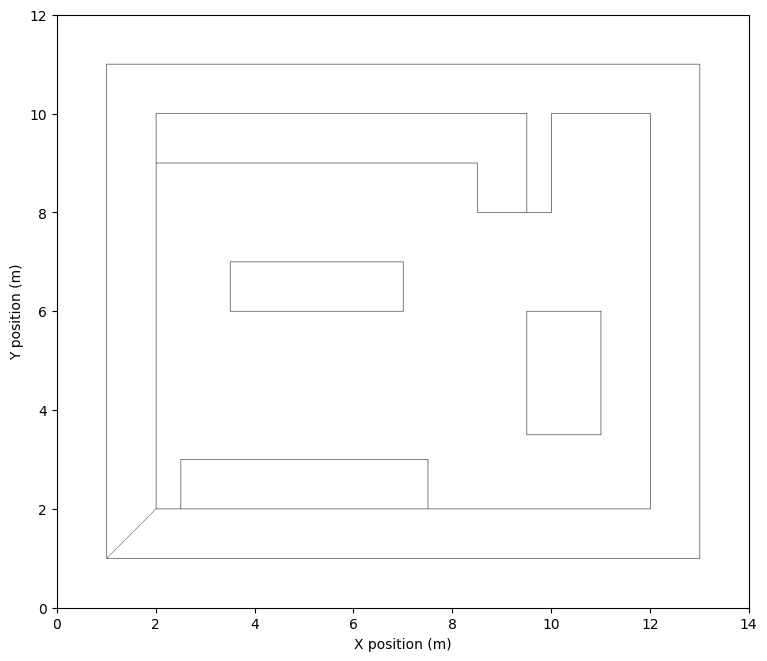

In [4]:
occupancy_map.show_occupancy();

- And the likelihood field

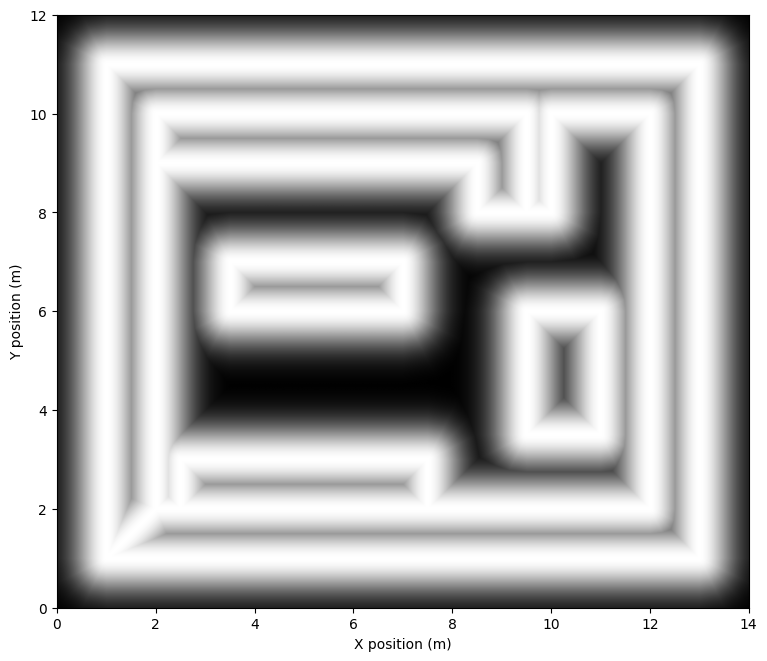

In [5]:
occupancy_map.show_likelihood();

For each point of the environment (a pixel in the image), the likelihood field expresses how likely it is that a point of the laser scan falls there. The intuition is that, although the measurements are noisy, the measured points should still be *close* to the surfaces of the obstacles: the further away from them, the less likely we are to observe anything there.

Formally, this is $p(\mathbf{z}^w_k \mid \mathbf{m})$, where $\mathbf{z}^w_k$ is a point of the world-space point cloud $\mathbf{z}^w$, and $\mathbf{m}$ is the map. Crucially, it does not depend on the robot pose $\mathbf{x}$, only on the geometry of the map and the reliability of the sensor. It is a simplified model (e.g., it ignores whether a laser beam could actually reach each point), but it gives good results in practice and is easy to generate.

Using the likelihood field, we can now answer our previous question: if the robot was *here*, how well does my observation fit the map?

## 5.3.2 Implementing the Particle Filter building blocks <a id="532"></a>

We will now look at each of the steps that go into creating the Particle Filter algorithm, individually:

1. [Propagating the particles between iterations (**prediction**)](#5321).
2. [Evaluating the particles (**correction**)](#5322).
   - [Estimating the real pose from the particles](#pose_estimation), when we need a single pose.
3. [Replacing bad particles with better ones (**resampling**)](#5323).

These are the 2+1 steps of the Bayes filter seen in theory (see Fig. 1). Then, once we have collected all the pieces, we'll assemble the puzzle and get the full picture.

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-3-pf-overview.gif" width="1100" alt="">
  <figcaption>Fig. 1. One cycle of the Particle Filter. In the prediction, each particle is moved with its own noisy copy of the motion command $\mathbf{u}_t$, so the cloud spreads. In the correction, each particle is weighted by how well the scan $\mathbf{z}_t$ fits the map from its pose. Then, the pose is estimated as the weighted mean of the particles $E[\mathbf{x}_t]$, which gives a single pose when we need one. In the resampling, $M$ particles are drawn according to their weights, so the good ones are copied and the bad ones disappear.</figcaption>
</figure>

### 1. Propagating the particles between iterations (prediction) <a id="5321"></a>

First of all, where do the particles come from? Well, initially, they are just generated around the starting pose of the robot. We can do this by just taking samples of the pose's probability distribution, like we did all the way at the beginning.

Each particle is represented by the `Particle` class below, which holds the pose that the particle represents and its weight. There is also an already implemented `normalize_weights()` function, which makes sure all the weights add up to 1 (we will need it later on):

In [6]:
class Particle:
    def __init__(self, pose, weight):
        self.pose = pose
        self.weight = weight

# This just makes it so the sum of all the weights is equal to 1
def normalize_weights(particles):
    total_weight = 0.
    for particle in particles:
        total_weight += particle.weight

    for particle in particles:
        particle.weight /= total_weight

In [7]:
def generate_particles(num_particles, pose, covariance):
    particles : list[Particle] = []
    for i in range(num_particles):
        particle_pose = np.vstack(stats.multivariate_normal.rvs(pose.flatten(), covariance))
        particles.append(Particle(particle_pose, 1. / num_particles)) # equal weight to start with, we don't yet know how good these particles are
    return particles

After that, the particles are propagated between iterations by **sampling**, which implements the **prediction** step of the filter. This is easy enough: we take each particle from the previous iteration, $\mathbf{x}_{t-1}^{[i]}$, and we draw its new pose from the motion model, given the movement $\mathbf{u}_t$ that the robot tried to do:

$$
\mathbf{x}_t^{[i]} \sim p(\mathbf{x}_t \mid \mathbf{x}_{t-1}^{[i]}, \mathbf{u}_t), \quad i = 1, \dots, M
$$

This is how the Particle Filter computes the prior $\overline{bel}(\mathbf{x}_t)$: instead of solving the integral of the prediction step, it draws a sample for each particle. The key is that, since the movement has uncertainty, each particle receives its own noisy movement $\mathbf{u}_t^{[i]}$, which doesn't perfectly correspond to the control action. This noisy movement is generated by using the covariance of the movement, $\Sigma_{\mathbf{u}_t}$, to sample its probability distribution. The new pose of the particle is then:

$$
\mathbf{x}_t^{[i]} = \mathbf{x}_{t-1}^{[i]} \oplus \mathbf{u}_t^{[i]}, \quad \mathbf{u}_t^{[i]} \sim \mathcal{N}(\mathbf{u}_t, \Sigma_{\mathbf{u}_t})
$$

### **<span style="color:green"><b><i>ASSIGNMENT 1: Sampling particles</i></b></span>**  

Complete the `sample_motion_model()` function below, which takes the pose of a particle $\mathbf{x}_{t-1}^{[i]}$, a movement command expressed as a pose increment $\mathbf{u}_t = [\Delta x, \Delta y, \Delta \theta]^T$ and its covariance $\Sigma_{\mathbf{u}_t}$, and returns a sample of the new pose $\mathbf{x}_t^{[i]}$, following the expression above.

Then, complete the `sample()` function, which takes a list of particles (representing hypotheses for the pose of the robot) and a movement command, and uses `sample_motion_model()` to move each of the particles.

In [8]:
def sample_motion_model(pose, movement, movement_covariance):
    # draw a noisy movement u_t^[i] ~ N(u_t, Sigma_u_t)
    noisy_movement = np.vstack(stats.multivariate_normal.rvs(movement.flatten(), movement_covariance))

    # x_t^[i] = x_{t-1}^[i] (+) u_t^[i]
    return tcomp(pose, noisy_movement)


def sample(particles, movement, movement_covariance):
    for particle in particles:
        particle.pose = sample_motion_model(particle.pose, movement, movement_covariance)

# function to plot the particles
def show_particles(particles, fig, ax, size = 0.002, color="cyan"):
    for particle in particles:
        DrawRobot(fig, ax, particle.pose, size, color=color)

Now test your code:

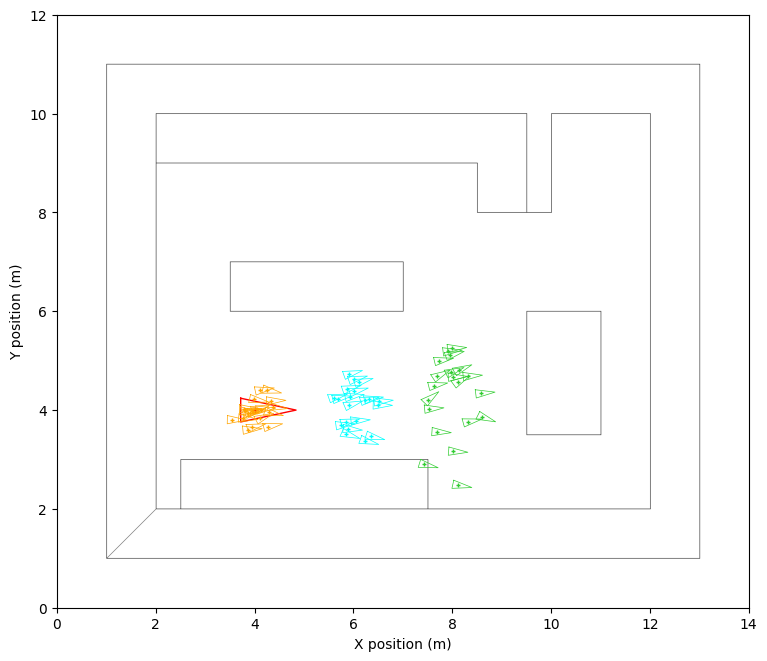

In [9]:
def test_sample_function():
    fig, ax = occupancy_map.show_occupancy()

    ideal_movement = np.vstack([2, 0, 0])
    movement_covariance = np.diag([0.02, 0.04, 0.02])
    
    # initial state
    initial_pose = np.vstack([4,4,0])
    initial_pose_cov = np.diag([0.05, 0.05, 0.04])
    DrawRobot(fig, ax, initial_pose, linewidth=1.)
    particles = generate_particles(20, initial_pose, initial_pose_cov)
    show_particles(particles, fig, ax, size=0.007, color="orange")
    
    # simulate one movement
    sample(particles, ideal_movement, movement_covariance)
    show_particles(particles, fig, ax, size=0.007, color="cyan")

    # simulate another movement
    sample(particles, ideal_movement, movement_covariance)
    show_particles(particles, fig, ax, size=0.007, color="limegreen")

test_sample_function()

<span style="color:blue">Expected output:</span>

<img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/particle_filter_prediction.png">

### 2. Evaluating the particles (correction) <a id="5322"></a>

Once the particles have been moved, we need to evaluate how good each of them is given the most recent observation, which is the core of the **correction** step.

### **<span style="color:green"><b><i>ASSIGNMENT 2: Evaluating particles</i></b></span>**  

Let's implement a function that takes in a map $\mathbf{m}$ and a point cloud $\mathbf{z}^w$ with $K$ points, which represents the endpoints of a scan captured by a 2D laser scanner expressed in world coordinates, and returns the likelihood $p(\mathbf{z}^w \mid \mathbf{m})$. The calculation we have to do is this:

$$
    p(\mathbf{z}^w \mid \mathbf{m}) \propto \prod_{k=1}^{K} p(\mathbf{z}^w_k \mid \mathbf{m})
$$

Remember that $p(\mathbf{z}^w_k \mid \mathbf{m})$ is precisely what the likelihood field represents. The expression above has a proportional-to sign rather than an equal sign, but do not worry. That simply means that there are some normalization terms involved that we are not going to calculate directly. Instead, we will do a normalization step later on, to make sure the probabilities add up to 1. 

To make things easier, we provide you with the function `LaserUtils.express_as_global_point_cloud(z, pose)`, which does something we already saw in the sensing chapter: takes the sensor reading expressed in local space and polar coordinates, and turns it into a global-space, cartesian point cloud (which is what you need to sample the likelihood field). Use it to also complete `evaluate_pose()`, which returns the likelihood of a scan $\mathbf{z}$ (in polar coordinates) taken from the pose $\mathbf{x}$.

The map class also provides a useful function: `sample_likelihood()`, which returns the value of the likelihood field at a specific coordinate of the map.

In [10]:
def evaluate_pointcloud(map : Map, pointcloud): 
    total_prob = 1
    
    for i in range(pointcloud.shape[1]):
        total_prob *= map.sample_likelihood(pointcloud[0:2, i])

    return total_prob

def evaluate_pose(map: Map, z, pose):
    world_pointcloud = LaserUtils.express_as_global_point_cloud(z, pose)
    return evaluate_pointcloud(map, world_pointcloud)

Now check that your function is right!

Likelihood of point cloud: 0.7653936384712728


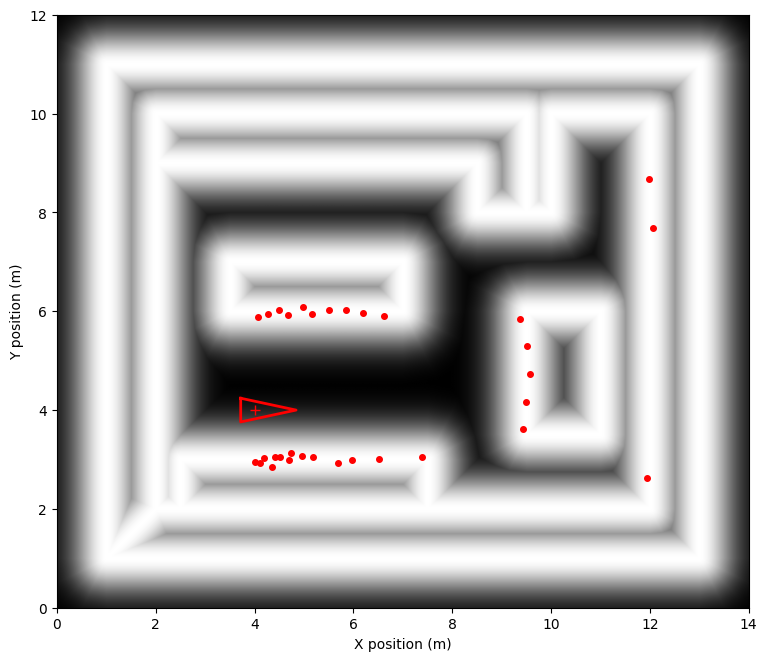

In [11]:
def test_evaluate_pointcloud():
    pose =  np.vstack([4,4,0])
    laser = Laser2D(np.pi, 0.1, 10, np.diag([0.01, 0.0]), pose)
    z = laser.take_observation(virtual_map)

    likelihood = evaluate_pose(occupancy_map, z, pose)
    print(f"Likelihood of point cloud: {likelihood}")
    
    # Plot
    fig, ax = occupancy_map.show_likelihood()
    DrawRobot(fig, ax, pose, linewidth=2)
    LaserUtils.plot_observations(z, pose, ax, draw_lines=False)

# Set a seed for random numbers
np.random.seed(42)

test_evaluate_pointcloud()

<span style="color:blue">Expected output:</span>

```
Likelihood of point cloud: 0.7653936384712728
```

<img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/likelihood_field_with_scan.PNG">

Ok, that gives us a number for how believable this point cloud is, but that's not terribly useful on its own. The point is that it lets us **compare** point clouds. To get the world-space point cloud $\mathbf{z}^w$ from a sensor reading $\mathbf{z}_c$ (in cartesian coordinates), we need the pose of the robot $\mathbf{x}$:

$$ \mathbf{z}^w = \mathbf{x} \oplus \mathbf{z}_c $$

So, if we use each candidate pose (particle) $\mathbf{x}^{[i]}$ to project the same reading, evaluating the resulting point cloud is equivalent to evaluating the pose itself: we get the likelihood of the observation given that pose, $p(\mathbf{z} \mid \mathbf{x}^{[i]}, \mathbf{m})$. This is what will let us estimate the real pose.

Let's take that next step, then: evaluate the three candidate poses below with your brand new `evaluate_pose()` function, and think about why each one gets its evaluation, comparing it with the real pose the measurement was taken from (in red).

Particle 1 (blue): 9.69779341922232e-06
Particle 2 (green): 0.2699737678772269
Particle 3 (magenta): 1.2663698201453412e-06


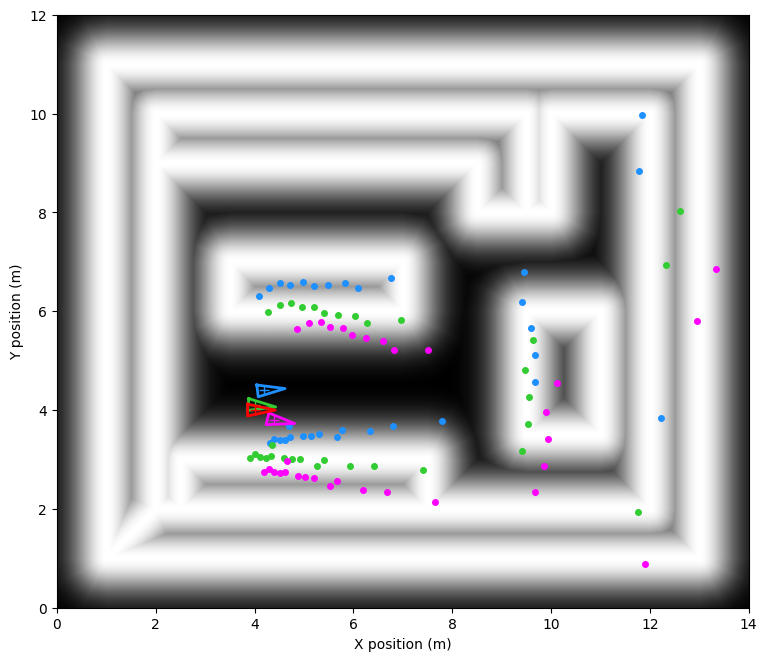

In [12]:
def PlotParticle(fig, ax, pose, z, color):
    DrawRobot(fig, ax, pose, 0.01, linewidth=2, color=color)
    LaserUtils.plot_observations(z, pose, ax, draw_lines=False, point_color=color)

def test_particle_evaluation():
    true_pose =  np.vstack([4,4,0])
    laser = Laser2D(np.pi, 0.1, 10, np.diag([0.01, 0.0]), true_pose)
    z = laser.take_observation(virtual_map)

    pose_particle1 = np.vstack([4.2, 4.4, 0.1])
    pose_particle2 = np.vstack([4.01, 4.1, -0.1])
    pose_particle3 = np.vstack([4.4, 3.8, -0.2])

    # plot
    fig, ax = occupancy_map.show_likelihood()
    PlotParticle(fig, ax, pose_particle1, z, "dodgerblue")
    PlotParticle(fig, ax, pose_particle2, z, "limegreen")
    PlotParticle(fig, ax, pose_particle3, z, "magenta")
    DrawRobot(fig, ax, true_pose, 0.01, linewidth=2, color="red")

    # evaluate the particles
    eval_1 = evaluate_pose(occupancy_map, z, pose_particle1)
    eval_2 = evaluate_pose(occupancy_map, z, pose_particle2)
    eval_3 = evaluate_pose(occupancy_map, z, pose_particle3)

    #print evaluations
    print(f"Particle 1 (blue): {eval_1}")
    print(f"Particle 2 (green): {eval_2}")
    print(f"Particle 3 (magenta): {eval_3}")

test_particle_evaluation()

<p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>La partícula verde, casi en la pose real, proyecta los extremos del láser sobre las paredes del mapa, donde el likelihood es alto. Las poses azul y magenta están desplazadas y giradas: muchos puntos caen fuera de las paredes y reciben valores pequeños; al multiplicarlos, la evaluación total cae mucho.</i></p>

<span style="color:blue">Expected output:</span>

```
Particle 1 (blue): 9.697793288623095e-06
Particle 2 (green): 0.2699737678772269
Particle 3 (magenta): 1.2663658417295267e-06
```

<img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/likelihood_field_with_particle_evaluations_v2.png">

#### Estimating the real pose from the particles <a id="pose_estimation"></a>

So, if we have a list of particles representing possible values for the pose of the robot, and we can evaluate how good each of them are, how do we turn that into a single estimation of the *real* pose? Strictly speaking, this is not a step of the filter, which keeps the whole belief $bel(\mathbf{x}_t)$ as the set of particles, but we need it whenever we want a single pose, for example to control the robot or to show where it is.

Probability theory gives us the perfect tool for this: the **expected value**. This is the same as the mean of a probability distribution, and can be very easily computed as a weighted average, where the weights are the probabilities of each value:

$$
E[X] = \sum_x p(x) \cdot x
$$

Since we don't quite have a probability distribution, but instead a set of $M$ particles, our computation is instead:

$$
E[\mathbf{x}_t] \approx \sum_{i=1}^{M} \tilde{w}_t^{[i]} \cdot \mathbf{x}_t^{[i]}
$$

where $\mathbf{x}_t^{[i]}$ is the pose represented by particle $i$, and $\tilde{w}_t^{[i]}$ is its weight normalized so that all the weights add up to 1:

$$
\tilde{w}_t^{[i]} = \frac{w_t^{[i]}}{\sum_{j=1}^{M} w_t^{[j]}}
$$

We can also calculate the uncertainty of our current particle distribution by using this expected value to get the covariance matrix associated with our estimated pose. To keep things simple, we will only compute its diagonal, that is, the variance of each component of the pose. The variance of a variable $X$ is defined as:

$$
\sigma^2_X = E[(X-E[X])^2]
$$

So, in our case, being $x_t^{[i]}$ and $y_t^{[i]}$ the position of particle $i$:

$$
\sigma^2_x \approx \sum_{i=1}^{M} \tilde{w}_t^{[i]} \cdot (x_t^{[i]}-E[x_t])^2
$$

$$
\sigma^2_y \approx \sum_{i=1}^{M} \tilde{w}_t^{[i]} \cdot (y_t^{[i]}-E[y_t])^2
$$

The orientation $\theta$ needs special care, since angles cannot be averaged directly (the mean of $179^\circ$ and $-179^\circ$ is not $0^\circ$!). Instead, its expected value $E[\theta_t]$ is the angle of the weighted average of the unit vectors $(\cos\theta_t^{[i]}, \sin\theta_t^{[i]})$, the so-called [*circular mean*](https://en.wikipedia.org/wiki/Circular_mean). The length $R$ of that average vector tells us how concentrated the orientations are, from 0 (totally spread) to 1 (all equal), so the *circular variance* $1 - R$ is used in place of $\sigma^2_\theta$. Note that it is a value between 0 and 1, not a variance in $\text{rad}^2$.

### **<span style="color:green"><b><i>ASSIGNMENT 3: Estimating the real pose from the particle evaluations</i></b></span>**  

Let's implement a function, `current_estimation()`, which receives a list of pre-evaluated particles and returns the expected value of the pose, along with the covariance of that estimation. Since averaging angles is a little tricky, and we don't expect you to be an expert on circular statistics, you just need to handle the *position* part of the pose.

Remember that the weight of each particle is the one it was assigned by the likelihood evaluation in the previous step, and that the provided `normalize_weights()` function computes the normalized weights $\tilde{w}_t^{[i]}$.

In [13]:
def current_estimation(particles):
    normalize_weights(particles)
    
    # we cannot just average angles, so instead we separate position and heading direction
    # averaging the (vector) heading directions is the most common definition of "circular mean" (https://en.wikipedia.org/wiki/Circular_mean)
    expected_value_position = np.vstack([0., 0.])
    expected_value_direction = np.vstack([0., 0.])

    # calculate the expected values (weighted average)
    for particle in particles:
        position = particle.pose[0:2]
        angle = particle.pose[2, 0]

        expected_value_position += position * particle.weight
        expected_value_direction += np.vstack([np.cos(angle), np.sin(angle)]) * particle.weight

    # get the angle value from the averaged directions
    expected_angle = np.atan2(expected_value_direction[1], expected_value_direction[0]) 
    expected_angle = np.vstack([expected_angle])

    # Calculate the expected value of the robot pose
    expected_pose = np.concatenate([expected_value_position, expected_angle], 0)

    # Calculate the diagonal elements of the covariance matrix (the variances), ignoring the covariances between components
    var_x = 0.
    var_y = 0.
    for particle in particles:
        var_x += particle.weight * (particle.pose[0, 0] - expected_pose[0, 0])**2
        var_y += particle.weight * (particle.pose[1, 0] - expected_pose[1, 0])**2

    # circular variance is inversely proportional to the length of the circular mean vector
    angular_variance = 1 - np.linalg.norm(expected_value_direction)
    covariance = np.diag([var_x, var_y, angular_variance])
    return expected_pose, covariance


Let's use this, then. We'll create a few random particles and evaluate each one. Then, we will look at those evaluations to extract the expected value and covariance of the estimated pose of the robot. In the figure, the particles are shown in blue, with an area proportional to their weight, the real pose in red, and the estimated pose in green, with the ellipse of its uncertainty.

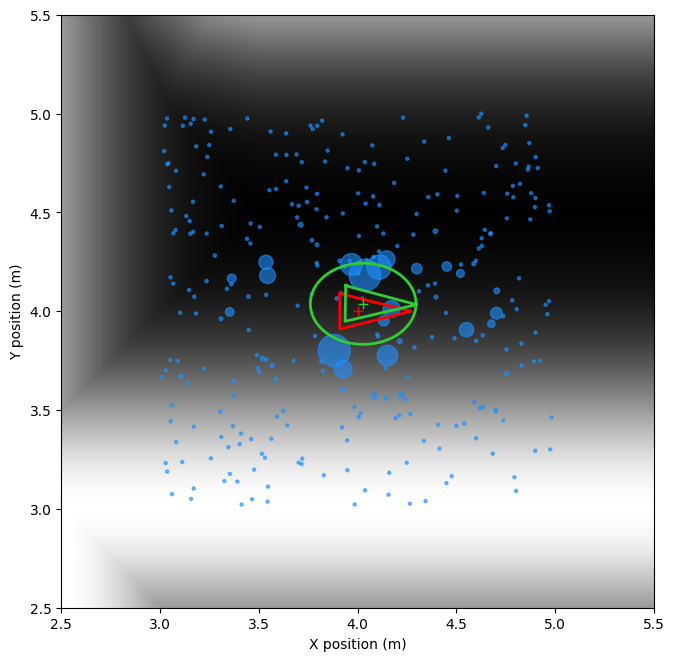

In [14]:
def test_estimate_pose():
    true_pose =  np.vstack([4,4,0])
    laser = Laser2D(np.pi, 0.1, 10, np.diag([0.01, 0.0]), true_pose)
    z = laser.take_observation(virtual_map)
    
    num_particles = 300
    particles = []
    for i in range(num_particles):
        # uniformly distributed random particles in the general vicinity of the real pose
        pose_particle = np.vstack([
            (np.random.rand()-0.5) * 2 + true_pose[0],
            (np.random.rand()-0.5) * 2 + true_pose[1],
            (np.random.rand()-0.5) * 1 + true_pose[2],
        ])
        # get the evaluation for this random pose and add it to the list
        weight = evaluate_pose(occupancy_map, z, pose_particle)
        particles.append(Particle(pose_particle, weight))

    # use the particles and their evaluations to estimate the real pose
    estimated_pose, estimated_cov = current_estimation(particles)
    
    # plot, zooming in on the particles
    fig, ax = occupancy_map.show_likelihood()
    ax.set_xlim([2.5, 5.5])
    ax.set_ylim([2.5, 5.5])

    # particles, with an area proportional to their (normalized) weight
    positions = np.hstack([particle.pose[0:2] for particle in particles])
    weights = np.array([particle.weight for particle in particles])
    ax.scatter(positions[0], positions[1], s=5 + 3000*weights, color="dodgerblue", alpha=0.6)

    DrawRobot(fig, ax, true_pose, 0.03, linewidth=2, color="red")
    DrawRobot(fig, ax, estimated_pose, 0.03, linewidth=2, color="limegreen")
    PlotEllipse(fig, ax, estimated_pose[0:2], estimated_cov, color="limegreen", linewidth=2)

test_estimate_pose()

<span style="color:blue">Expected output:</span>

<img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/likelihood_field_with_estimated_pose_particles.png">

We can see the expected value does not always give us a perfect estimation, but it tends to be quite close. If we increase the number of particles, the estimations tend to be more reliable and the uncertainty is lower. Try different numbers of particles and check this for yourself!

### 3. Replacing bad particles with better ones (resampling) <a id="5323"></a>

After the correction step, some of the particles will have a very low weight, so they are not very interesting. Rather than keep propagating these bad estimations, we would prefer to allocate our computational resources to evaluating candidate poses that are more likely to be close to the correct value. *That* is the idea behind **resampling** (*survival of the fittest*): we draw a new set of $M$ particles from the current one, with replacement, so that the probability of drawing each particle is its normalized weight $\tilde{w}_t^{[i]}$. Particles with large weights are likely to be selected several times, while those with small weights are likely to disappear. This implementation of the Particle Filter is known as **SIR** (*Sequential Importance Resampling*).

### **<span style="color:green"><b><i>ASSIGNMENT 4: Resampling particles</i></b></span>**  

Complete the `resample()` function below, which takes a list of particles and returns the resampled one. As seen in theory, this is done in two steps (see Fig. 2):

1. Build the cumulative distribution of the normalized weights, where particles with larger weights occupy larger intervals:

   $$
   C_k = \sum_{i=1}^{k} \tilde{w}_t^{[i]}, \quad k = 1, \dots, M, \quad C_M = 1
   $$

2. Draw $M$ random numbers $r_j \sim U(0,1)$, $j = 1, \dots, M$, and, for each $r_j$, select the particle whose cumulative-weight interval contains it, that is, the particle $k$ such that $C_{k-1} < r_j \leq C_k$ (with $C_0 = 0$).

After resampling, all the particles have the same weight:

$$
\{\mathbf{x}_t^{[i]}, \tilde{w}_t^{[i]}\}_{i=1}^{M} \xrightarrow{\text{resampling}} \{\mathbf{x}_t^{[i]}, 1/M\}_{i=1}^{M}
$$

<center><figure style="text-align:center">
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-3-sir-resampling.png" width="800" alt="">
    <figcaption>Fig. 2. SIR resampling of $M = 6$ weighted particles: the random numbers $r_j$ fall more often in the wide intervals of the cumulative distribution, so particles with larger weights are selected several times, while those with small weights tend to disappear.</figcaption>
</figure></center>

*Tip: the NumPy functions [`np.cumsum()`](https://numpy.org/doc/stable/reference/generated/numpy.cumsum.html) and [`np.searchsorted()`](https://numpy.org/doc/stable/reference/generated/numpy.searchsorted.html) can do each of these steps in a single line.*

In [15]:
def resample(particles):
    M = len(particles)
    normalize_weights(particles)

    # 1. Cumulative distribution of the normalized weights, C_k
    cumulative = np.cumsum([particle.weight for particle in particles])
    cumulative[-1] = 1. # make sure that C_M = 1 despite round-off errors

    # 2. Draw M random numbers r_j ~ U(0,1), and get for each one the index of the particle whose interval contains it
    r = np.random.uniform(0, 1, M)
    selected = np.searchsorted(cumulative, r)

    # The resampled particles are copies of the selected ones, all with weight 1/M
    return [Particle(particles[k].pose.copy(), 1. / M) for k in selected]

Test the resampling with the following code. The red robot is the initial pose, and the orange one is the real pose after the movement. The particles before resampling are shown in grey, and the resampled ones in cyan, with a circle whose area is proportional to the number of times each one was selected.

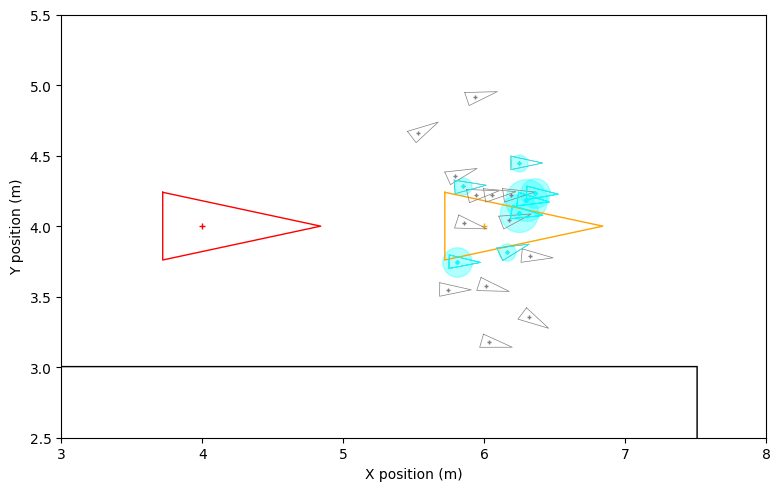

In [16]:
def test_resampling():
    fig, ax = occupancy_map.show_occupancy()

    movement = np.vstack([2, 0, 0])
    movement_covariance = np.diag([0.02, 0.04, 0.02])

    # initial state
    initial_pose = np.vstack([4,4,0])
    initial_pose_cov = np.diag([0.05, 0.05, 0.04])
    particles = generate_particles(20, initial_pose, initial_pose_cov)
    DrawRobot(fig, ax, initial_pose, linewidth=1.)

    # move and sample (prediction)
    real_pose = tcomp(initial_pose, movement)
    sample(particles, movement, movement_covariance)
    DrawRobot(fig, ax, real_pose, linewidth=1., color="orange")
    show_particles(particles, fig, ax, size=0.004, color="grey")

    # evaluate (correction)
    laser = Laser2D(np.pi, 0.1, 10, np.diag([0.01, 0.0]), real_pose)
    z = laser.take_observation(virtual_map)
    for particle in particles:
        particle.weight = evaluate_pose(occupancy_map, z, particle.pose)

    # resample
    particles = resample(particles)
    show_particles(particles, fig, ax, size=0.004, color="cyan")

    # show how many times each particle was selected (circle area proportional to its number of copies)
    copies = Counter(tuple(particle.pose.flatten()) for particle in particles)
    for (x, y, theta), n in copies.items():
        ax.scatter(x, y, s=150*n, color="cyan", alpha=0.3, zorder=0)

    # zoom in on the particles
    ax.set_xlim([3, 8])
    ax.set_ylim([2.5, 5.5])


test_resampling()

<span style="color:blue">Expected output:</span>

<img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/particle_filter_sir_resampling.png">

## 5.3.3 Assembling the Particle Filter <a id="533"></a>

We now have all the pieces of the particle filter, so let's put them in order and see the algorithm come to life.

### **<span style="color:green"><b><i>ASSIGNMENT 5: Putting all together</i></b></span>**  

First, complete the body of the function `update_weights()` in the `ParticleFilter` class below. This is the **correction** step: the weight of each particle at time instant $t$ is updated with the likelihood of the most recent observation $\mathbf{z}_t$ given the pose of that particle (which we calculated in the evaluation section):

$$
w_t^{[i]} \propto w_{t-1}^{[i]} \cdot p(\mathbf{z}_t \mid \mathbf{x}_t^{[i]}, \mathbf{m})
$$

Since after resampling all the particles have the same weight, $w_{t-1}^{[i]} = 1/M$, this is equivalent to the $w_t^{[i]} \propto p(\mathbf{z}_t \mid \mathbf{x}_t^{[i]})$ seen in theory.

In [17]:
class ParticleFilter:
    def __init__(self, initial_pose):
        # You can play with the number of particles M
        num_particles = 50
        self.particles = generate_particles(num_particles, initial_pose, np.diag([0,0,0]))

    def update_weights(self, map, z):
        for particle in self.particles:
            particle.weight *= evaluate_pose(map, z, particle.pose)

        normalize_weights(self.particles)

Now, let's run the particle filter algorithm! Complete the main loop below to estimate the pose of the robot as it moves around the environment. You will need to use the functions that we have defined previously in the notebook for each of the steps.

The core process is as follows:

- **Prediction**: apply the movement command to all particles (sampling).
- **Correction**: update the weight of each particle given the most recent measurement.
- Calculate the estimated pose and its associated uncertainty.
- **Resampling**: draw a new set of particles according to their weights.

In the figure, the red robot is the pose that the robot would reach if its movements were perfect, the blue one is its true pose, and the green one is the pose estimated by the filter. The current particles are shown in cyan, and those of the previous iteration in light grey.

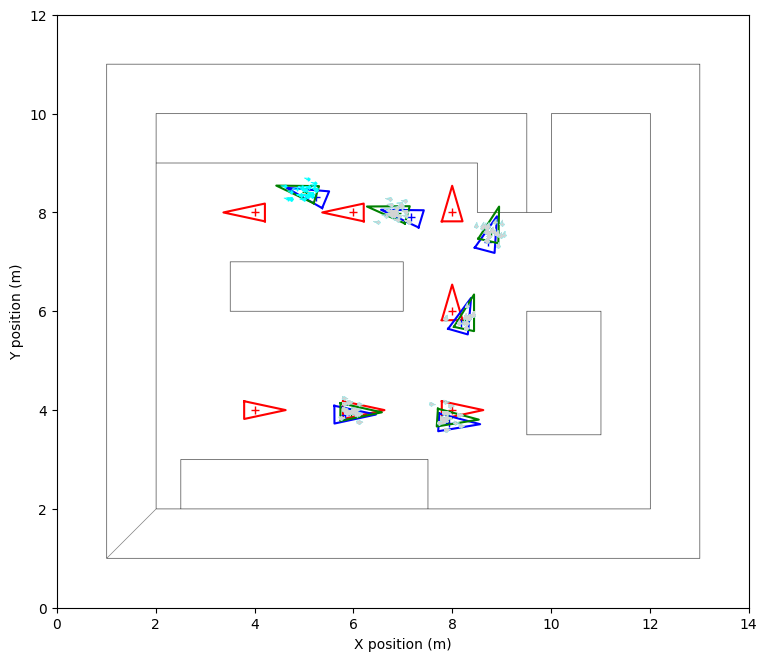

In [18]:
def test_particle_filter():
    true_pose = np.vstack([4,4,0])
    ideal_pose = true_pose 

    movements = [
        np.vstack([2, 0, 0]),
        np.vstack([2, 0, 0]),
        np.vstack([0, 2, np.pi/2]),
        np.vstack([2, 0, 0]),
        np.vstack([0, 2, np.pi/2]),
        np.vstack([2, 0, 0]),
    ]
    cov = np.diag([0.02, 0.02, 0.01])

    laser = Laser2D(np.pi, 0.1, 10, np.diag([0.01, 0.0]), true_pose)
    pf = ParticleFilter(true_pose)

    fig, ax = occupancy_map.show_occupancy()
    DrawRobot(fig, ax, ideal_pose, 0.015, linewidth=1.5, color="red")

    old_particles=[]

    for move in movements:
        # -----------------------------------------------------------------
        # SIMULATION: the robot moves and takes a scan (unknown to the filter)
        # -----------------------------------------------------------------
        # pose that the robot would reach if its movement were perfect (red)
        ideal_pose = tcomp(ideal_pose, move)
        DrawRobot(fig, ax, ideal_pose, 0.015, linewidth=1.5, color="red")

        # true pose, after a noisy movement (blue)
        true_pose = sample_motion_model(true_pose, move, cov)
        DrawRobot(fig, ax, true_pose, 0.015, linewidth=1.5, color="blue")

        # laser scan z_t taken from the true pose
        laser.set_pose(true_pose)
        z = laser.take_observation(virtual_map)

        # -----------------------------------------------------------------
        # PARTICLE FILTER
        # -----------------------------------------------------------------
        # 1. Prediction: move each particle with the motion model, x_t^[i] ~ p(x_t | x_{t-1}^[i], u_t)
        sample(pf.particles, move, cov)

        # 2. Correction: weight each particle with the scan, w_t^[i] proportional to p(z_t | x_t^[i], m)
        pf.update_weights(occupancy_map, z)

        #    Pose estimation (when we need a single pose): weighted mean of the particles, E[x_t]
        estimated_pose, estimated_covariance = current_estimation(pf.particles)

        # 3. Resampling: draw M particles with replacement according to their weights
        pf.particles = resample(pf.particles)

        # -----------------------------------------------------------------
        # PLOTS
        # -----------------------------------------------------------------
        # estimated pose (green)
        DrawRobot(fig, ax, estimated_pose, 0.015, linewidth=1.5, color="green")
        # PlotEllipse(fig, ax, estimated_pose[0:2], estimated_covariance, color="green")

        # current particles (cyan) and those of the previous iteration (light grey)
        show_particles(pf.particles, fig, ax, color = "cyan")
        show_particles(old_particles, fig, ax, color = "lightgrey")
        old_particles = copy.deepcopy(pf.particles)

        # keep updating the plot on the same figure
        display(fig)        
        clear_output(wait=True)
        time.sleep(0.1)


test_particle_filter()

<span style="color:blue">Expected output:</span>

<img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/particle_filter_localization_sir.png">

So that's the algorithm! As you can see, the process is conceptually much simpler than something like EKF, given we are always operating on specific poses rather than probability distributions, but there is a price to pay in terms of computational complexity and accuracy.

Still, Monte Carlo methods are very powerful tools, and very commonly used. Their ability to represent any type of distribution (rather than being constrained to gaussian approximations) means they are very flexible. The implementation we have explored here is a relatively simplistic one, but making only a few changes you could represent multi-modal distributions, consider whether specific trajectories would collide with obstacles, *etc.* 

## <font color="orange"><b><i>AI Appendix</i></b></font>

### A.1 How I used AI
- **Model/tool:**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Asistente de programación Devin con GPT-6 Luna High Thinking.</i></p>
- **What I asked AI to help with (bullets):**
  <div style="margin: 4px 0px 6px 5px; color:#2DD4BF; font-style: italic"><ul><li>Completar el modelo de movimiento, la evaluación de point clouds, la estimación ponderada y el remuestreo del filtro de partículas.</li><li>Integrar predicción, corrección, estimación y remuestreo, y comprobar las salidas numéricas esperadas.</li><li>Explicar por qué una pose de partícula compatible con las paredes obtiene mayor likelihood que las poses desplazadas.</li></ul></div>
- **Best prompt I used (paste):**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"></p>
- **What I kept vs. changed from the AI output:**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>He aplicado las soluciones indicadas sin cambiar las semillas ni las clases del profesor. La verosimilitud del scan de la celda 26 coincide con la esperada y la partícula 2 también; las partículas 1 y 3 difieren ligeramente. Es probable que influya la versión de NumPy/SciPy de este entorno frente a la fijada por el curso. No forcé los valores ni alteré el código para ocultar la diferencia. La covarianza cero de <code>ParticleFilter</code> sí funciona con el SciPy instalado.</i></p>

### A.2 AI review
Ask one generative AI to review your memo using this prompt:

```
Act as a technical reviewer of this robotics notebook. Read my memo and return exactly 5 bullet points:

- two on theory (key ideas),
- two on practice (relevant programming concepts of python used, not particular functions or variables),
- one on how to improve the code (most critical aspect: limitations, parameter choices, runtime/robustness, possible bugs).

Keep each bullet ≤15 words and make them specific to my work.
```

Paste its **5** items here:

*AI used for the review: the same AI assistant (Devin with GPT-6 Luna High Thinking).*

- **(Theory 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Las partículas representan la creencia como muestras ponderadas y propagan incertidumbre mediante movimientos aleatorios.</i></p>
- **(Theory 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Los likelihoods ajustan los pesos; el remuestreo concentra partículas en las poses compatibles con el scan.</i></p>
- **(Practice 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>El slicing conserva las dimensiones de posición y selecciona las coordenadas del point cloud.</i></p>
- **(Practice 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>La suma acumulada y la búsqueda ordenada implementan muestreo inverso con reemplazo.</i></p>
- **(Improvement)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>El producto de muchos likelihoods pequeños puede subdesbordarse; acumular log-verosimilitudes mejora la robustez.</i></p>

Finally, **do you agree with them?**, **would you have selected others?**
    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Estoy de acuerdo con los cinco puntos. El primero resume la representación Monte Carlo y el segundo, la corrección con la observación y la selección de hipótesis. Las dos observaciones de Python describen las dimensiones y el muestreo acumulado que usa el código. La mejora es importante para scans más largos: multiplicar muchos valores pequeños puede llevar a cero por precisión finita; acumular log-likelihoods evita ese subdesbordamiento, aunque exigiría adaptar la normalización de pesos.</i></p>